Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -q /content/drive/MyDrive/SANDRA/dataset.zip -d/content/

Mounted at /content/drive


Intalll ultralytics

In [2]:
%pip install ultralytics
%pip install -U ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 48.3/112.6 GB disk)


In [3]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

results = model.train(
    data = '/content/dataset/data.yaml',
    epochs = 50,
    imgsz = 640,
    batch = 16,
    project = '/content/drive/MyDrive/SANDRA/yolo_runs',
    name = 'SANDRA_yolo26n'
)


Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=SANDRA_yolo26n-2, nbs=64, nms=None, opset=None, op

In [4]:
from ultralytics import YOLO

# Load the best weights generated from your training run
model = YOLO('/content/drive/MyDrive/SANDRA/yolo_runs/SANDRA_yolo26n-2/weights/best.pt')

# Execute validation on the val split defined in data.yaml
metrics = model.val(data='/content/dataset/data.yaml')

# Print table header
print(f"\n{'Category':<15} | {'Precision':<9} | {'Recall':<9} | {'mAP@50':<9} | {'mAP@50-95':<9}")
print("-" * 65)

# Loop through each individual class detected during validation
for i, c in enumerate(metrics.box.ap_class_index):
    name = metrics.names[c]
    p = metrics.box.p[i]
    r = metrics.box.r[i]
    map50 = metrics.box.ap50[i]
    map95 = metrics.box.ap[i]
    print(f"{name:<15} | {p:<9.4f} | {r:<9.4f} | {map50:<9.4f} | {map95:<9.4f}")

print("-" * 65)

# Extract and print the master overall metrics (The 7th Category)
overall_p = metrics.box.mp
overall_r = metrics.box.mr
overall_map50 = metrics.box.map50
overall_map = metrics.box.map
print(f"{'ALL (Overall)':<15} | {overall_p:<9.4f} | {overall_r:<9.4f} | {overall_map50:<9.4f} | {overall_map:<9.4f}")

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3557.8±1809.5 MB/s, size: 315.7 KB)
val: Scanning /content/dataset/val/labels.cache... 400 images, 195 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 400/400 129.1Mit/s 0.0s
val: /content/dataset/val/images/s109_jpg.rf.ebf3d521457594f0b455e74a3a39958f.jpg: ignoring corrupt image/label: labels mix segment and detection rows
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 52, len(boxes) = 308. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 4.6it/s 5.4s
                   all        399        308       0.68      0.60


image 1/98 /content/dataset/test/images/000023_jpg.rf.cd067115ac89eb3aede0164bae2c2f17.jpg: 640x640 (no detections), 8.7ms
image 2/98 /content/dataset/test/images/000032_jpg.rf.830934e9aec278a1aac2c775b2bf7e63.jpg: 640x640 1 plane, 11.0ms
image 3/98 /content/dataset/test/images/000042_jpg.rf.30ab03388e2e77741e388c8fc0776b0b.jpg: 640x640 1 plane, 11.4ms
image 4/98 /content/dataset/test/images/000071_jpg.rf.8ea06a81b8debfcdd1d722fd9f0fcab3.jpg: 640x640 1 plane, 10.3ms
image 5/98 /content/dataset/test/images/000077_jpg.rf.1c2ae26ffc5189190123781aeb040084.jpg: 640x640 1 shipwreck, 2 planes, 9.7ms
image 6/98 /content/dataset/test/images/000132_jpg.rf.f2ba423ba22a7c3e4d7700d635aab568.jpg: 640x640 3 debriss, 10.4ms
image 7/98 /content/dataset/test/images/000152_jpg.rf.4e45f061a8c0cf2ac9fe40c516d7d8be.jpg: 640x640 1 debris, 12.2ms
image 8/98 /content/dataset/test/images/000160_jpg.rf.316a812180e05f5a6682948a1c1a8422.jpg: 640x640 (no detections), 14.7ms
image 9/98 /content/dataset/test/images/

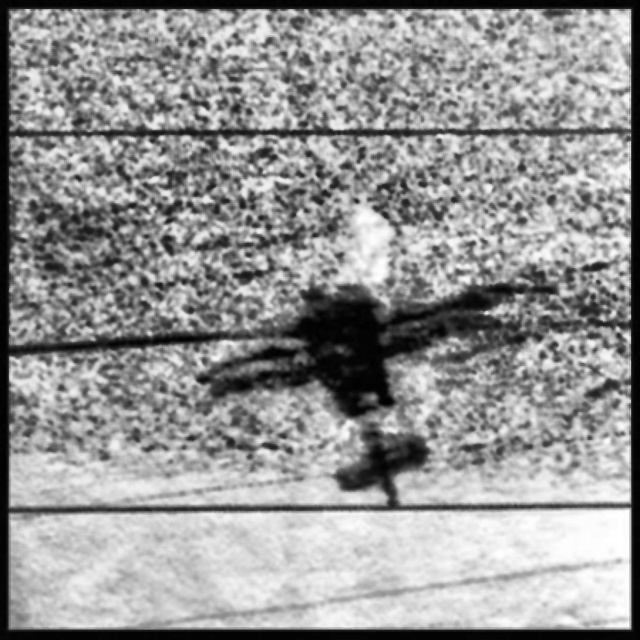

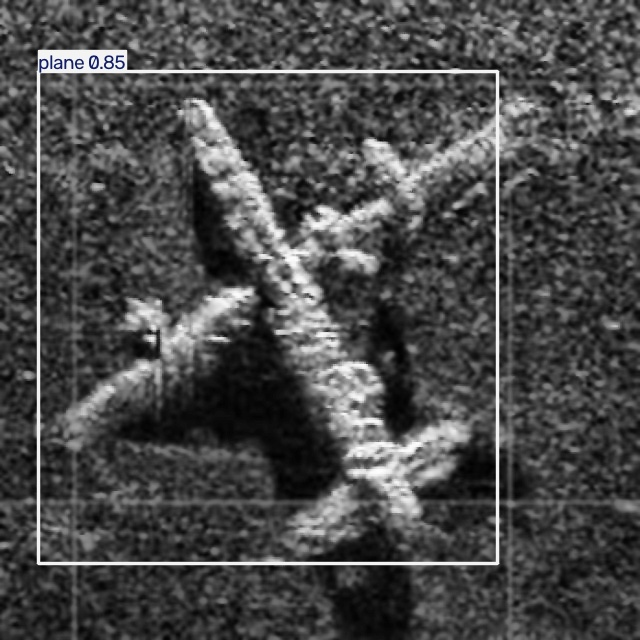

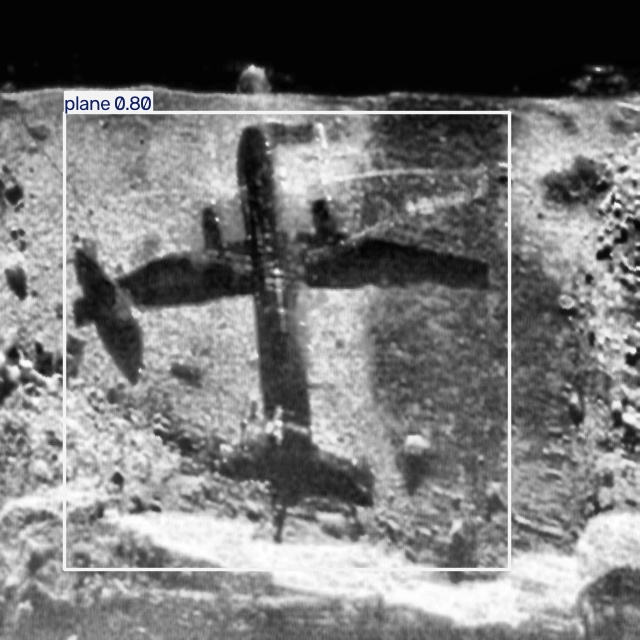

In [5]:
import glob
from IPython.display import Image, display
from ultralytics import YOLO

# Load your trained weights
model = YOLO('/content/drive/MyDrive/SANDRA/yolo_runs/SANDRA_yolo26n-2/weights/best.pt')

# Run inference on the test images (confidence threshold 0.25)
model.predict(source='/content/dataset/test/images', save=True, conf=0.25, project='/content/drive/MyDrive/SANDRA/yolo_runs', name='test_inference')

# Display the first 3 annotated images directly in Colab
saved_images = glob.glob('/content/drive/MyDrive/SANDRA/yolo_runs/test_inference/*.jpg')
for img in saved_images[:3]:
    display(Image(filename=img))

In [6]:
from ultralytics import YOLO

# Load a fresh model so it learns from scratch at the new resolution
new_model = YOLO('yolo26n.pt')

# Start high-res training
results = new_model.train(
    data='/content/dataset/data.yaml',
    epochs=100,
    imgsz=1024,
    batch=16,
    project='/content/drive/MyDrive/SANDRA/yolo_runs',
    name='sonar_detection_1024'
)

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=sonar_detection_1024, nbs=64, nms=None, opset=No

In [7]:
from ultralytics import YOLO

# Load the best weights generated from your training run
model = YOLO('/content/drive/MyDrive/SANDRA/yolo_runs/sonar_detection_1024/weights/best.pt')

# Execute validation on the val split defined in data.yaml
metrics = model.val(data='/content/dataset/data.yaml')

# Print table header
print(f"\n{'Category':<15} | {'Precision':<9} | {'Recall':<9} | {'mAP@50':<9} | {'mAP@50-95':<9}")
print("-" * 65)

# Loop through each individual class detected during validation
for i, c in enumerate(metrics.box.ap_class_index):
    name = metrics.names[c]
    p = metrics.box.p[i]
    r = metrics.box.r[i]
    map50 = metrics.box.ap50[i]
    map95 = metrics.box.ap[i]
    print(f"{name:<15} | {p:<9.4f} | {r:<9.4f} | {map50:<9.4f} | {map95:<9.4f}")

print("-" * 65)

# Extract and print the master overall metrics (The 7th Category)
overall_p = metrics.box.mp
overall_r = metrics.box.mr
overall_map50 = metrics.box.map50
overall_map = metrics.box.map
print(f"{'ALL (Overall)':<15} | {overall_p:<9.4f} | {overall_r:<9.4f} | {overall_map50:<9.4f} | {overall_map:<9.4f}")

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2871.3±1950.0 MB/s, size: 388.6 KB)
val: Scanning /content/dataset/val/labels.cache... 400 images, 195 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 400/400 111.8Mit/s 0.0s
val: /content/dataset/val/images/s109_jpg.rf.ebf3d521457594f0b455e74a3a39958f.jpg: ignoring corrupt image/label: labels mix segment and detection rows
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 52, len(boxes) = 308. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 2.3it/s 10.7s
                   all        399        308      0.691      0.6

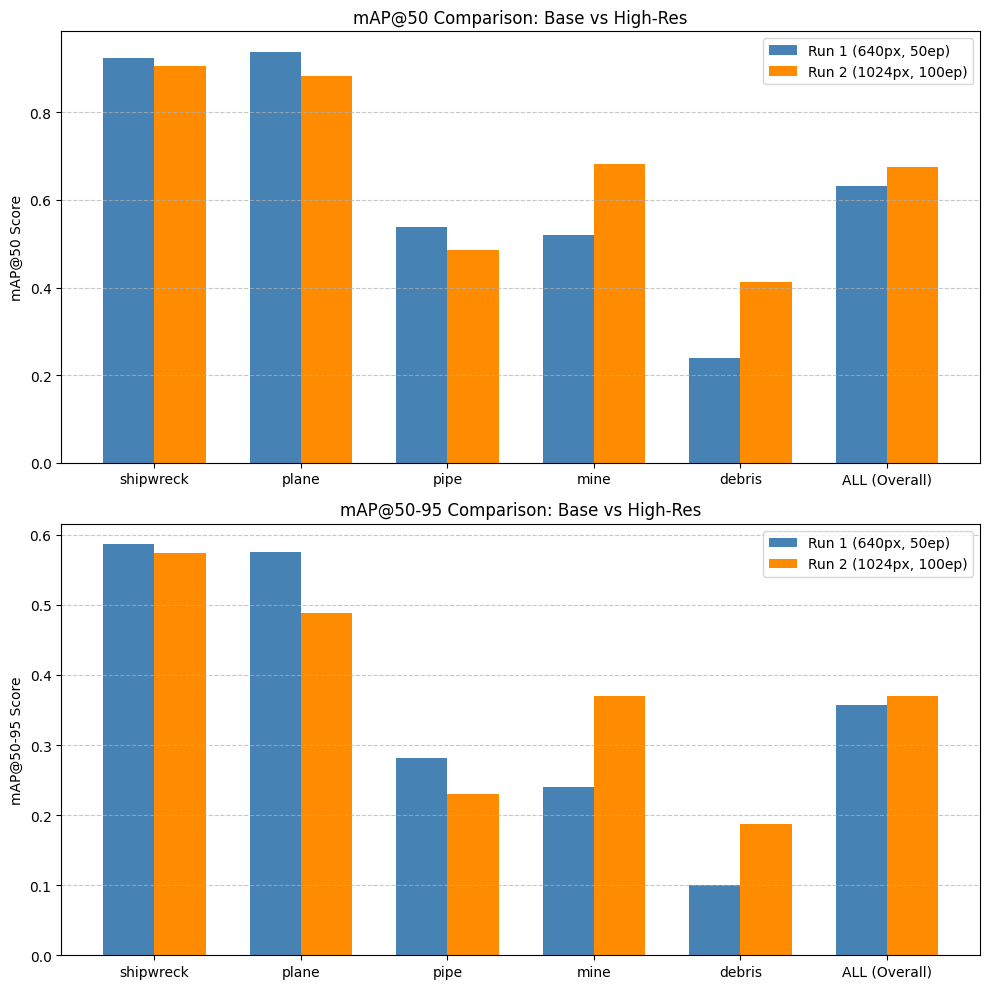

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Categories
categories = ['shipwreck', 'plane', 'pipe', 'mine', 'debris', 'ALL (Overall)']

# Previous Run (Run 1: 50 epochs, imgsz=640)
run1_map50 = [0.9237, 0.9380, 0.5373, 0.5202, 0.2403, 0.6319]
run1_map95 = [0.5863, 0.5750, 0.2817, 0.2406, 0.1002, 0.3568]

# Current Run (Run 2: 100 epochs, imgsz=1024)
run2_map50 = [0.9052, 0.8840, 0.4858, 0.6825, 0.4133, 0.6742]
run2_map95 = [0.5742, 0.4878, 0.2300, 0.3705, 0.1868, 0.3699]

x = np.arange(len(categories))
width = 0.35

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

# Plot mAP@50
ax1.bar(x - width/2, run1_map50, width, label='Run 1 (640px, 50ep)', color='steelblue')
ax1.bar(x + width/2, run2_map50, width, label='Run 2 (1024px, 100ep)', color='darkorange')
ax1.set_ylabel('mAP@50 Score')
ax1.set_title('mAP@50 Comparison: Base vs High-Res')
ax1.set_xticks(x)
ax1.set_xticklabels(categories)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Plot mAP@50-95
ax2.bar(x - width/2, run1_map95, width, label='Run 1 (640px, 50ep)', color='steelblue')
ax2.bar(x + width/2, run2_map95, width, label='Run 2 (1024px, 100ep)', color='darkorange')
ax2.set_ylabel('mAP@50-95 Score')
ax2.set_title('mAP@50-95 Comparison: Base vs High-Res')
ax2.set_xticks(x)
ax2.set_xticklabels(categories)
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()